In [47]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import DataLoader, Dataset, TensorDataset,random_split
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline, Pipeline
from sklearn.metrics import accuracy_score, f1_score
from sklearn.metrics import accuracy_score
import mlflow
import mlflow.sklearn
import mlflow.pytorch
import joblib   
import tempfile
import os
import joblib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

SEED = 20

In [13]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Using device: cpu


In [14]:
iris = load_iris()

X = iris.data.astype(np.float32)
y = iris.target.astype(np.int64)

print("Dimensions X :", X.shape)
print("Dimensions y :", y.shape)
print("Classes :", iris.target_names)

Dimensions X : (150, 4)
Dimensions y : (150,)
Classes : ['setosa' 'versicolor' 'virginica']


In [15]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state= SEED)

In [16]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [38]:
X_train_tensor = torch.tensor(X_train_scaled, dtype=torch.float32)
y_train_tensor= torch.tensor(y_train, dtype=torch.long)
X_test_tensor = torch.tensor(X_test_scaled, dtype=torch.float32)
y_test_tensor= torch.tensor(y_test, dtype=torch.long)
train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
test_dataset = TensorDataset(X_test_tensor, y_test_tensor)
train_dl = DataLoader(train_dataset, batch_size=16, shuffle=True)
test_dl = DataLoader(test_dataset, batch_size=16, shuffle=False)


In [25]:
mlflow.set_tracking_uri("sqlite:///mlflow.db")
experiment_name = "Iris_PyTorch_Sklearn"
mlflow.set_experiment(experiment_name)
iris_model ={}
run_id={}

2026/11/25 23:29:19 INFO mlflow.tracking.fluent: Experiment with name 'Iris_PyTorch_Sklearn' does not exist. Creating a new experiment.


### Premiere experience 

In [28]:
model_sk = Pipeline([
    ('scaler', StandardScaler()),
    ('classifier', LogisticRegression( C=1.0,
                                      max_iter=100,                                                 
        random_state=SEED)) ])
with mlflow.start_run(run_name="sklearn_logistic_regression") as run:
    model_sk.fit(X_train, y_train)
    pred_train = model_sk.predict(X_train)
    pred_test = model_sk.predict(X_test)
    train_acc = accuracy_score(y_train, pred_train)
    test_acc = accuracy_score(y_test, pred_test)
    test_f1 = f1_score(y_test, pred_test, average='macro')
    
    mlflow.log_params({
        "framework": "sklearn",
        "model_type": "LogisticRegression",
        "C": 1.0,
        "max_iter": 100})
    
    mlflow.log_metrics({
        "train_accuracy": train_acc,
        "test_accuracy": test_acc,
        "test_f1_score": test_f1})
    
    model_info = mlflow.sklearn.log_model(model_sk, "model",
                                          input_example=X_train[:2])
    mlflow.set_tag(
        "model_uri",
        model_info.model_uri
    )
     
    mlflow.set_tag("model_uri", model_info.model_uri)
    
    iris_model["Sklearn_Logistic"] = model_info.model_uri
    
    run_id["Sklearn_Logistic"] = run.info.run_id
    
print(f"Accuracy train : {train_acc:.4f}")
print(f"Accuracy test  : {test_acc:.4f}")
print(f"F1-score test  : {test_f1:.4f}")




2026/11/25 23:30:19 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/11/25 23:30:19 INFO mlflow.utils.uv_utils: Detected uv project: found uv.lock and pyproject.toml in /home/romaric/pytorch
2026/11/25 23:30:19 INFO mlflow.utils.uv_utils: Detected uv project: found uv.lock and pyproject.toml in /home/romaric/pytorch
2026/11/25 23:30:19 INFO mlflow.utils.environment: Detected uv project at /home/romaric/pytorch. Attempting to export requirements via 'uv export'.
2026/11/25 23:30:19 INFO mlflow.utils.uv_utils: Exported 128 dependencies via uv
2026/11/25 23:30:19 INFO mlflow.utils.environment: Successfully exported 128 requirements from uv project. Skipping package capture based inference.
2026/11/25 23:30:19 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.


Accuracy train : 0.9583
Accuracy test  : 0.9333
F1-score test  : 0.9389


## Construire le réseau de neurones PyTorch

In [39]:
class IrisNet(nn.Module):
    
    def __init__(self,hidden_size = 16) :
        super().__init__()
        self.fc1 = nn.Linear(4,hidden_size)
        self.fc2 = nn.Linear(hidden_size,3)
    
    def forward(self,x):
        x = F.relu(self.fc1(x))
        x = F.dropout(x, p=0.3)
        x = self.fc2(x)
        return x

In [54]:
def train_pytorch(hidden_size=16,epochs=100,learning_rate=0.01
):

    torch.manual_seed(SEED)

    model = IrisNet(hidden_size=hidden_size)

    criterion = nn.CrossEntropyLoss()

    optimizer = optim.Adam(
        model.parameters(),
        lr=learning_rate
    )

    history = []

    name = f"PyTorch_hidden_{hidden_size}"

    with mlflow.start_run(run_name=name) as run:

        mlflow.log_params({
            "framework": "pytorch",
            "hidden_size": hidden_size,
            "epochs": epochs,
            "learning_rate": learning_rate,
            "batch_size": 16,
            "optimizer": "Adam"
        })

        for epoch in range(1, epochs + 1):

            model.train()

            running_loss = 0.0

            for xb, yb in train_dl:

                # Remise à zéro des gradients
                optimizer.zero_grad()

                # Forward propagation
                pred = model(xb)

                # Fonction de perte
                loss = criterion(pred, yb)

                # Backpropagation
                loss.backward()

                # Mise à jour des poids
                optimizer.step()

                running_loss += loss.item() * len(xb)

            epoch_loss = running_loss / len(train_dataset)

            # Enregistrer la loss par époque
            history.append(epoch_loss)

            mlflow.log_metric(
                "train_loss",
                epoch_loss,
                step=epoch
            )

            if epoch % 10 == 0:
                print(
                    f"{name} | "
                    f"Epoch {epoch}/{epochs} | "
                    f"Loss = {epoch_loss:.4f}"
                )

        # 3. Évaluation finale
        model.eval()

        with torch.no_grad():

            train_logits = model(X_train_tensor)
            test_logits = model(X_test_tensor)

            pred_train = train_logits.argmax(dim=1).numpy()
            pred_test = test_logits.argmax(dim=1).numpy()

        train_acc = accuracy_score(y_train, pred_train)
        test_acc = accuracy_score(y_test, pred_test)

        test_f1 = f1_score(
            y_test,
            pred_test,
            average="macro"
        )

        # 4. Enregistrement des métriques
        mlflow.log_metrics({
            "train_accuracy": train_acc,
            "test_accuracy": test_acc,
            "test_f1_macro": test_f1
        })

        # 5. Sauvegarder le modèle
        model_info = mlflow.pytorch.log_model(
            pytorch_model=model,
            name="model",
            input_example=X_train_scaled[:2]
        )

        mlflow.set_tag(
            "model_uri",
            model_info.model_uri
        )

        # 6. Artefacts : scaler et courbe de loss
        with tempfile.TemporaryDirectory() as tmp:

            scaler_path = os.path.join(
                tmp, "scaler.joblib"
            )

            joblib.dump(scaler, scaler_path)

            mlflow.log_artifact(
                scaler_path,
                artifact_path="preprocessing"
            )

            plt.figure(figsize=(8, 4))
            plt.plot(history)
            plt.xlabel("Epoch")
            plt.ylabel("Training loss")
            plt.title(f"Loss - {name}")

            plot_path = os.path.join(
                tmp, "loss_curve.png"
            )

            plt.savefig(plot_path)
            plt.close()

            mlflow.log_artifact(
                plot_path,
                artifact_path="plots"
            )

        iris_model[name] = model_info.model_uri
        run_id[name] = run.info.run_id

    return model, history

In [55]:
model_16, history_16 = train_pytorch(
    hidden_size=16,
    epochs=100,
    learning_rate=0.01
)

PyTorch_hidden_16 | Epoch 10/100 | Loss = 0.2127
PyTorch_hidden_16 | Epoch 20/100 | Loss = 0.1034
PyTorch_hidden_16 | Epoch 30/100 | Loss = 0.0878
PyTorch_hidden_16 | Epoch 40/100 | Loss = 0.1078
PyTorch_hidden_16 | Epoch 50/100 | Loss = 0.0531
PyTorch_hidden_16 | Epoch 60/100 | Loss = 0.0583
PyTorch_hidden_16 | Epoch 70/100 | Loss = 0.0630
PyTorch_hidden_16 | Epoch 80/100 | Loss = 0.0521
PyTorch_hidden_16 | Epoch 90/100 | Loss = 0.0496


2026/11/26 00:27:05 INFO mlflow.utils.uv_utils: Detected uv project: found uv.lock and pyproject.toml in /home/romaric/pytorch


PyTorch_hidden_16 | Epoch 100/100 | Loss = 0.0729


2026/11/26 00:27:06 INFO mlflow.utils.uv_utils: Detected uv project: found uv.lock and pyproject.toml in /home/romaric/pytorch
2026/11/26 00:27:06 INFO mlflow.utils.environment: Detected uv project at /home/romaric/pytorch. Attempting to export requirements via 'uv export'.
2026/11/26 00:27:06 INFO mlflow.utils.uv_utils: Exported 128 dependencies via uv
2026/11/26 00:27:06 INFO mlflow.utils.environment: Successfully exported 128 requirements from uv project. Skipping package capture based inference.
2026/11/26 00:27:06 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.


In [59]:
experiment_results = mlflow.search_runs(
    experiment_names=[experiment_name]
)

# Retenir les runs de cette exécution
experiment_results = experiment_results[
    experiment_results["run_id"].isin(run_id.values())
]

comparison = experiment_results[
    [
        "tags.mlflow.runName",
        "params.framework",
        "metrics.train_accuracy",
        "metrics.test_accuracy",
        "metrics.test_f1_macro"
    ]
].sort_values(
    by="metrics.test_accuracy",
    ascending=False
)

display(comparison)

,tags.mlflow.runName,params.framework,metrics.train_accuracy,metrics.test_accuracy,metrics.test_f1_macro
1,PyTorch_hidden_16,pytorch,0.983333,0.966667,0.969634
9,sklearn_logistic_regression,sklearn,0.958333,0.933333,NaN
0,PyTorch_hidden_32,pytorch,0.983333,0.900000,0.907368


In [58]:
model_32, history_32 = train_pytorch(
    hidden_size=32,
    epochs=100,
    learning_rate=0.01
)

PyTorch_hidden_32 | Epoch 10/100 | Loss = 0.1451
PyTorch_hidden_32 | Epoch 20/100 | Loss = 0.1086
PyTorch_hidden_32 | Epoch 30/100 | Loss = 0.0913
PyTorch_hidden_32 | Epoch 40/100 | Loss = 0.0489
PyTorch_hidden_32 | Epoch 50/100 | Loss = 0.0352
PyTorch_hidden_32 | Epoch 60/100 | Loss = 0.0546
PyTorch_hidden_32 | Epoch 70/100 | Loss = 0.0508
PyTorch_hidden_32 | Epoch 80/100 | Loss = 0.0446
PyTorch_hidden_32 | Epoch 90/100 | Loss = 0.0331
PyTorch_hidden_32 | Epoch 100/100 | Loss = 0.0261


2026/11/26 00:36:01 INFO mlflow.utils.uv_utils: Detected uv project: found uv.lock and pyproject.toml in /home/romaric/pytorch
2026/11/26 00:36:01 INFO mlflow.utils.uv_utils: Detected uv project: found uv.lock and pyproject.toml in /home/romaric/pytorch
2026/11/26 00:36:01 INFO mlflow.utils.environment: Detected uv project at /home/romaric/pytorch. Attempting to export requirements via 'uv export'.
2026/11/26 00:36:01 INFO mlflow.utils.uv_utils: Exported 128 dependencies via uv
2026/11/26 00:36:01 INFO mlflow.utils.environment: Successfully exported 128 requirements from uv project. Skipping package capture based inference.
2026/11/26 00:36:01 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.


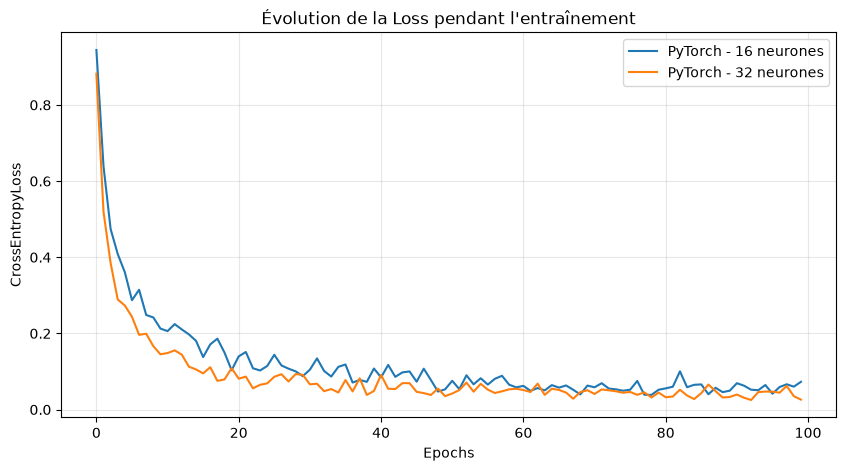

In [60]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.plot(history_16, label="PyTorch - 16 neurones")
plt.plot(history_32, label="PyTorch - 32 neurones")

plt.xlabel("Epochs")
plt.ylabel("CrossEntropyLoss")
plt.title("Évolution de la Loss pendant l'entraînement")

plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [61]:
experiment_results = mlflow.search_runs(
    experiment_names=[experiment_name]
)

# Retenir les runs de cette exécution
experiment_results = experiment_results[
    experiment_results["run_id"].isin(run_id.values())
]

comparison = experiment_results[
    [
        "tags.mlflow.runName",
        "params.framework",
        "metrics.train_accuracy",
        "metrics.test_accuracy",
        "metrics.test_f1_macro"
    ]
].sort_values(
    by="metrics.test_accuracy",
    ascending=False
)

display(comparison)

,tags.mlflow.runName,params.framework,metrics.train_accuracy,metrics.test_accuracy,metrics.test_f1_macro
1,PyTorch_hidden_16,pytorch,0.983333,0.966667,0.969634
9,sklearn_logistic_regression,sklearn,0.958333,0.933333,NaN
0,PyTorch_hidden_32,pytorch,0.983333,0.900000,0.907368
